# 02 · Exploratory Data Analysis

Questions this notebook answers:

1. How balanced are the appliances and their combinations?
2. What does each appliance "look like" electrically (power, current, power factor)?
3. Which combinations overlap and will be hard to separate?
4. How does the hair straightener behave over time (the key difference from the 100 W bulb)?
5. Which measurements should (and should not) be used as model inputs?
6. How should the data be split for honest evaluation?

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

sys.path.insert(0, str(Path.cwd().parent))
from src.config import APPLIANCES, APPLIANCE_NAMES, FIGURES_DIR
from src.data_loader import load_labelled, load_events

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 130, "savefig.bbox": "tight"})
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

COLORS = {"hair_dryer": "#d62728", "hair_straightener": "#9467bd", "bulb_200W": "#ff7f0e", "bulb_100W": "#2ca02c"}
SHORT = {"hair_dryer": "Dryer", "hair_straightener": "Straightener", "bulb_200W": "200W", "bulb_100W": "100W"}

def combo_name(code):
    on = [SHORT[a] for a, b in zip(APPLIANCES, code) if b == "1"]
    return " + ".join(on) if on else "All off"

def save(fig, name):
    fig.savefig(FIGURES_DIR / f"{name}.png")

df = load_labelled()
events = load_events()
df["combo_name"] = df["combo"].map(combo_name)
train, test = df[df.split == "train"], df[df.split == "test"]
# steady-state rows: no switching in progress, normal dryer setting
steady = df[(df.transition == 0) & (df.dryer_medium_setting == 0)]
print(df.shape, train.shape, test.shape, steady.shape)

(1370, 21) (1187, 21) (183, 21) (1069, 21)


## 1. Class balance

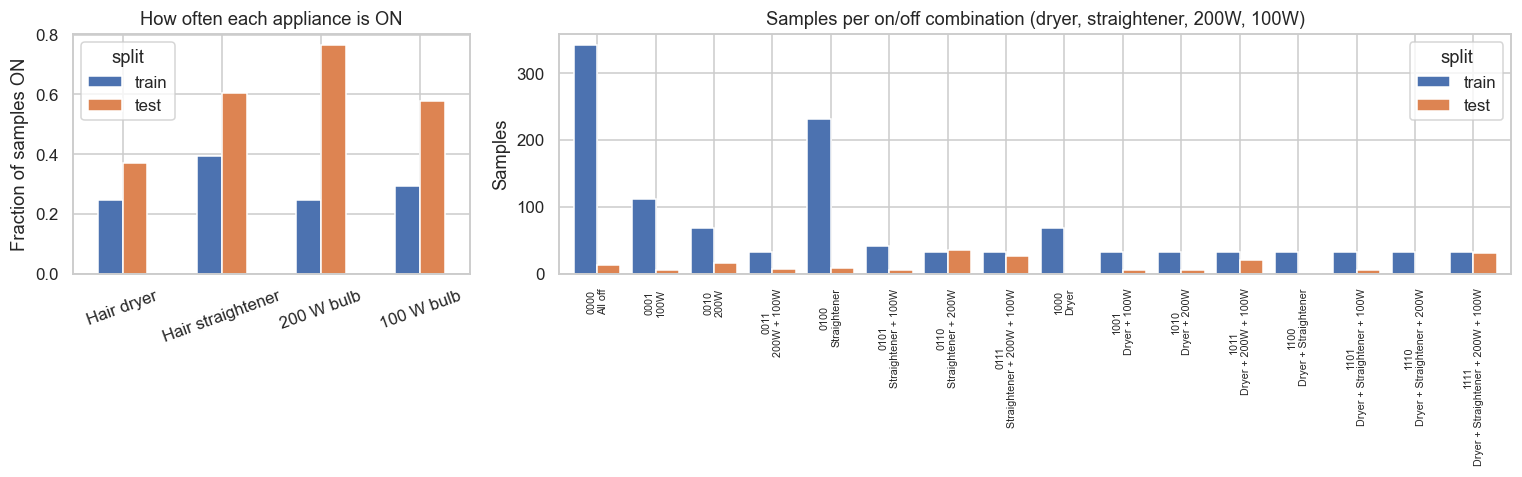

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1, 2.4]})

rate = df.groupby("split", observed=True)[APPLIANCES].mean().T
rate.index = [APPLIANCE_NAMES[a] for a in rate.index]
rate[["train", "test"]].plot.bar(ax=axes[0], color=["#4c72b0", "#dd8452"], rot=20)
axes[0].set_ylabel("Fraction of samples ON")
axes[0].set_title("How often each appliance is ON")

cc = pd.crosstab(df["combo"], df["split"])[["train", "test"]]
cc.index = [f"{c}\n{combo_name(c)}" for c in cc.index]
cc.plot.bar(ax=axes[1], color=["#4c72b0", "#dd8452"], width=0.8)
axes[1].set_title("Samples per on/off combination (dryer, straightener, 200W, 100W)")
axes[1].set_ylabel("Samples")
axes[1].tick_params(axis="x", labelsize=7, rotation=90)
fig.tight_layout(); save(fig, "01_class_balance"); plt.show()

- Training data covers **all 16 combinations** (≥ 32 samples each), but is dominated by *all off* and *straightener
  alone* (from the long heat-up block).
- The **test block** has appliances ON far more often (e.g. 200 W bulb 77 % vs 25 % in train) and three combinations
  never occur in it. Test accuracy will therefore depend heavily on the multi-appliance combinations.

## 2. Distribution of each measurement

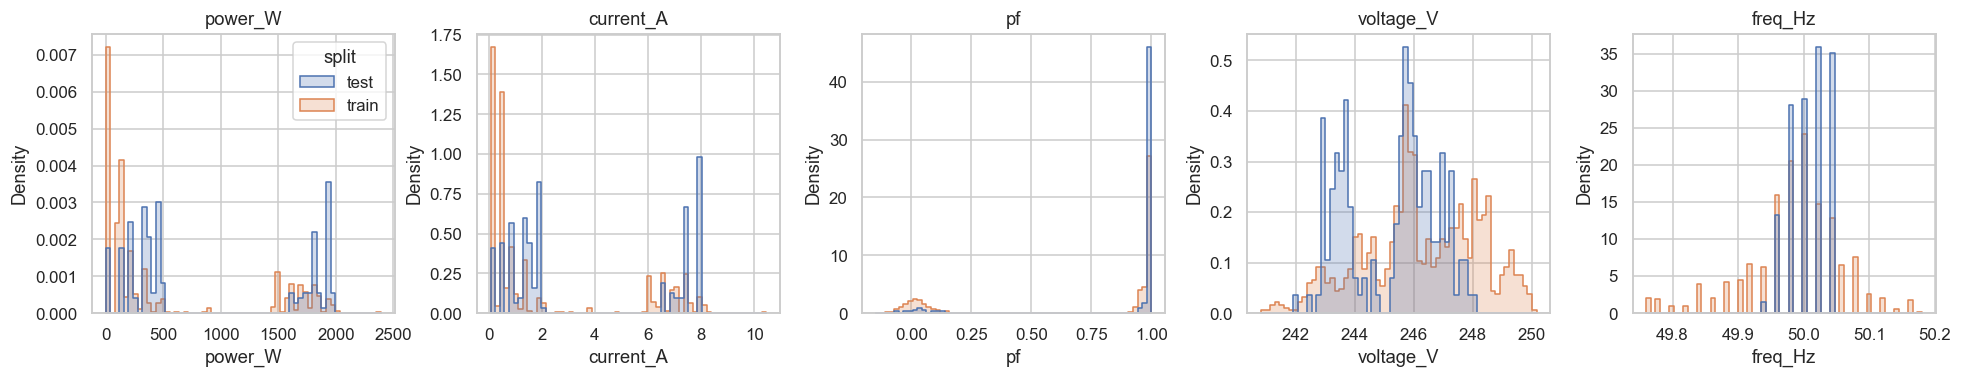

In [3]:
feats = ["power_W", "current_A", "pf", "voltage_V", "freq_Hz"]
fig, axes = plt.subplots(1, 5, figsize=(18, 3.6))
for ax, f in zip(axes, feats):
    sns.histplot(df, x=f, hue="split", bins=60, ax=ax, element="step", stat="density", common_norm=False)
    ax.set_title(f)
    if ax is not axes[0]:
        ax.get_legend().remove()
fig.tight_layout(); save(fig, "02_feature_distributions"); plt.show()

- **Power and current** are multi-modal: each peak is a group of appliance combinations. The large gap between
  ≈ 600 W and ≈ 1,450 W separates "dryer OFF" from "dryer ON".
- **Power factor** is ≈ 0 when nothing is on (noise around the sensor offset) and ≈ 1 for resistive loads.
- **Voltage and frequency** are supply properties, not appliance properties (checked in section 6).

## 3. Electrical signature of each appliance (alone)

In [4]:
single = steady[steady["num_devices_on"] <= 1].copy()
sig = (single.groupby("combo_name")
             .agg(samples=("power_W", "size"),
                  power_median=("power_W", "median"), power_min=("power_W", "min"), power_max=("power_W", "max"),
                  current_median=("current_A", "median"),
                  pf_median=("pf", "median"), pf_min=("pf", "min"))
             .round(3).sort_values("power_median"))
sig

,samples,power_median,power_min,power_max,current_median,pf_median,pf_min
combo_name,,,,,,,
All off,281,0.50,-3.3,3.9,0.098,0.022,-0.138
Straightener,212,115.95,96.7,212.6,0.494,0.962,0.877
100W,85,129.20,124.6,134.6,0.514,0.995,0.949
200W,59,226.50,222.0,230.6,0.910,1.000,0.981
Dryer,44,1490.50,1454.5,1511.5,6.094,1.000,0.990


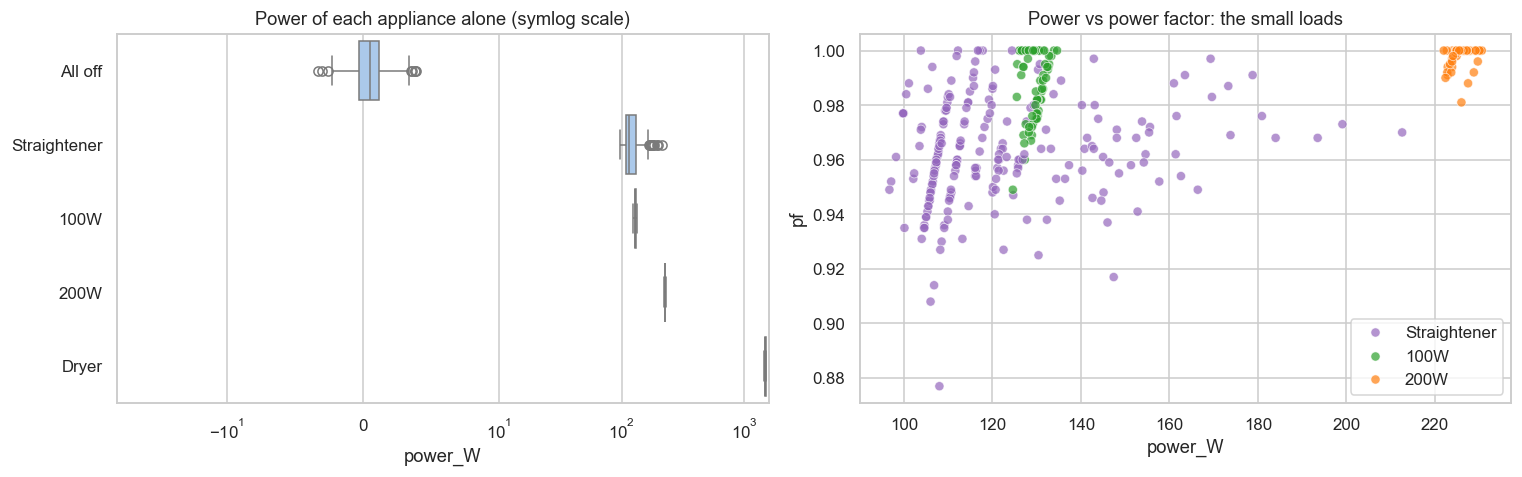

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
order = sig.index.tolist()
sns.boxplot(single, y="combo_name", x="power_W", order=order, ax=axes[0], color="#a1c9f4")
axes[0].set_xscale("symlog", linthresh=10)
axes[0].set_title("Power of each appliance alone (symlog scale)")
axes[0].set_ylabel("")

low = single[single["combo_name"].isin(["100W", "Straightener", "200W"])]
sns.scatterplot(low, x="power_W", y="pf", hue="combo_name", ax=axes[1], alpha=0.7,
                palette={"100W": COLORS["bulb_100W"], "Straightener": COLORS["hair_straightener"], "200W": COLORS["bulb_200W"]})
axes[1].set_title("Power vs power factor: the small loads")
axes[1].legend(title="")
fig.tight_layout(); save(fig, "03_single_appliance_signatures"); plt.show()

| Appliance | Power | PF | Comment |
|---|---|---|---|
| Hair dryer | ≈ 1,490 W | 1.00 | Far above everything else, trivial to detect |
| 200 W bulb | ≈ 227 W | 1.00 | Very stable |
| 100 W bulb | ≈ 129 W | ≈ 1.00 | Very stable |
| Hair straightener | 97 – 213 W | ≈ 0.96 | Power drifts down as it heats; slightly lower PF |

The **100 W bulb and the hot straightener overlap in power**. Power factor separates them partly (bulb ≈ 1.00,
straightener ≈ 0.96), but the clouds touch.

## 4. All 16 combinations: where do they overlap?

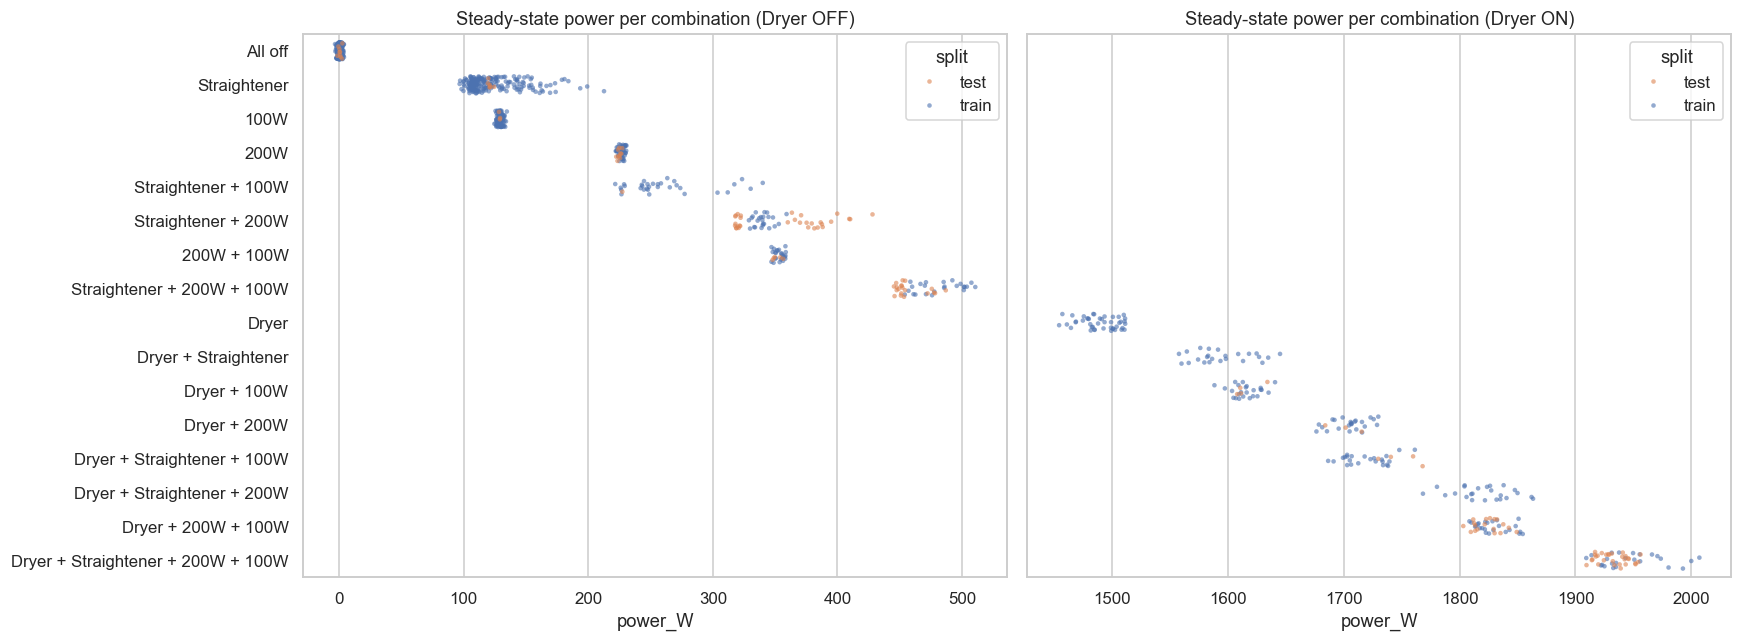

In [6]:
order = steady.groupby("combo_name")["power_W"].median().sort_values().index
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
for ax, (lo, hi), title in zip(axes, [(-10, 650), (1400, 2050)], ["Dryer OFF", "Dryer ON"]):
    sub = steady[(steady.power_W > lo) & (steady.power_W < hi)]
    sub_order = [o for o in order if o in sub.combo_name.unique()]
    sns.stripplot(sub, x="power_W", y="combo_name", order=sub_order, ax=ax, size=3, alpha=0.6, jitter=0.25,
                  hue="split", palette={"train": "#4c72b0", "test": "#dd8452"})
    ax.set_title(f"Steady-state power per combination ({title})")
    ax.set_ylabel("")
fig.tight_layout(); save(fig, "04_power_by_combination"); plt.show()

In [7]:
rng = (steady.groupby("combo_name")["power_W"]
             .agg(["min", "median", "max", "size"]).sort_values("median"))
rows = []
names = rng.index.tolist()
for i, a in enumerate(names):
    for b in names[i + 1:]:
        lo = max(rng.loc[a, "min"], rng.loc[b, "min"])
        hi = min(rng.loc[a, "max"], rng.loc[b, "max"])
        if hi > lo:
            rows.append({"combo A": a, "combo B": b, "overlap_from_W": lo, "overlap_to_W": hi,
                         "median_gap_W": abs(rng.loc[a, "median"] - rng.loc[b, "median"])})
overlaps = pd.DataFrame(rows).sort_values("median_gap_W")
overlaps.round(1)

,combo A,combo B,overlap_from_W,overlap_to_W,median_gap_W
6,Dryer + Straightener + 200W,Dryer + 200W + 100W,1803.2,1854.5,1.8
3,Straightener + 200W,200W + 100W,347.0,358.5,12.9
0,Straightener,100W,124.6,134.6,13.2
5,Dryer + 200W,Dryer + Straightener + 100W,1686.6,1729.9,20.5
1,200W,Straightener + 100W,222.0,230.6,22.4
4,Dryer + Straightener,Dryer + 100W,1588.5,1640.8,24.1
2,Straightener + 100W,Straightener + 200W,317.8,340.0,91.5


Every overlapping pair involves the **straightener swapping places with the 100 W bulb** (or with "nothing" near the
200 W bulb). The two most dangerous pairs, with almost identical median power, are:

- `Straightener + 200W` ↔ `200W + 100W` (≈ 340 W vs 353 W)
- `Dryer + Straightener + 200W` ↔ `Dryer + 200W + 100W` (≈ 1,823 W vs 1,825 W)

A model that only sees the **current** power level will confuse these. Extra information is needed: power factor,
and above all **history** (what switched on, and how).

## 5. Hair straightener behaviour over time

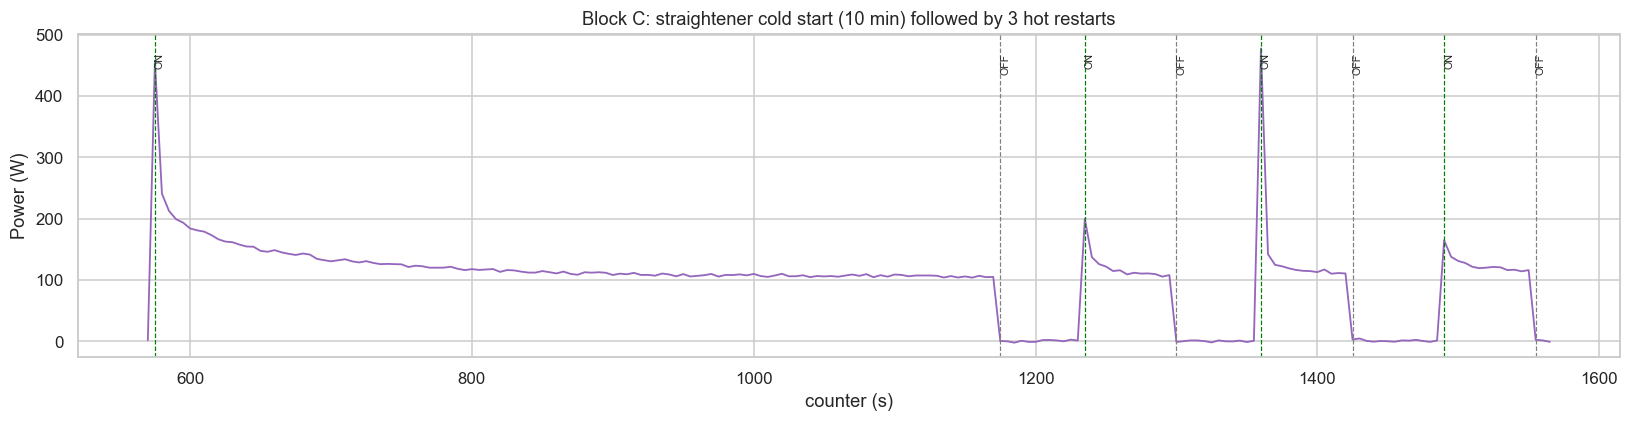

In [8]:
c = df[df.block == "C_straightener"].copy()
ev_c = events[events.block == "C_straightener"]

fig, ax = plt.subplots(figsize=(15, 4))
ax.plot(c["counter"], c["power_W"], lw=1.2, color=COLORS["hair_straightener"])
for _, e in ev_c.iterrows():
    ax.axvline(e["counter"], color="green" if e["action"] == "ON" else "grey", ls="--", lw=0.8)
    ax.text(e["counter"], ax.get_ylim()[1] if False else 470, e["action"], rotation=90, fontsize=7, va="top")
ax.set_xlabel("counter (s)"); ax.set_ylabel("Power (W)")
ax.set_title("Block C: straightener cold start (10 min) followed by 3 hot restarts")
fig.tight_layout(); save(fig, "05_straightener_block"); plt.show()

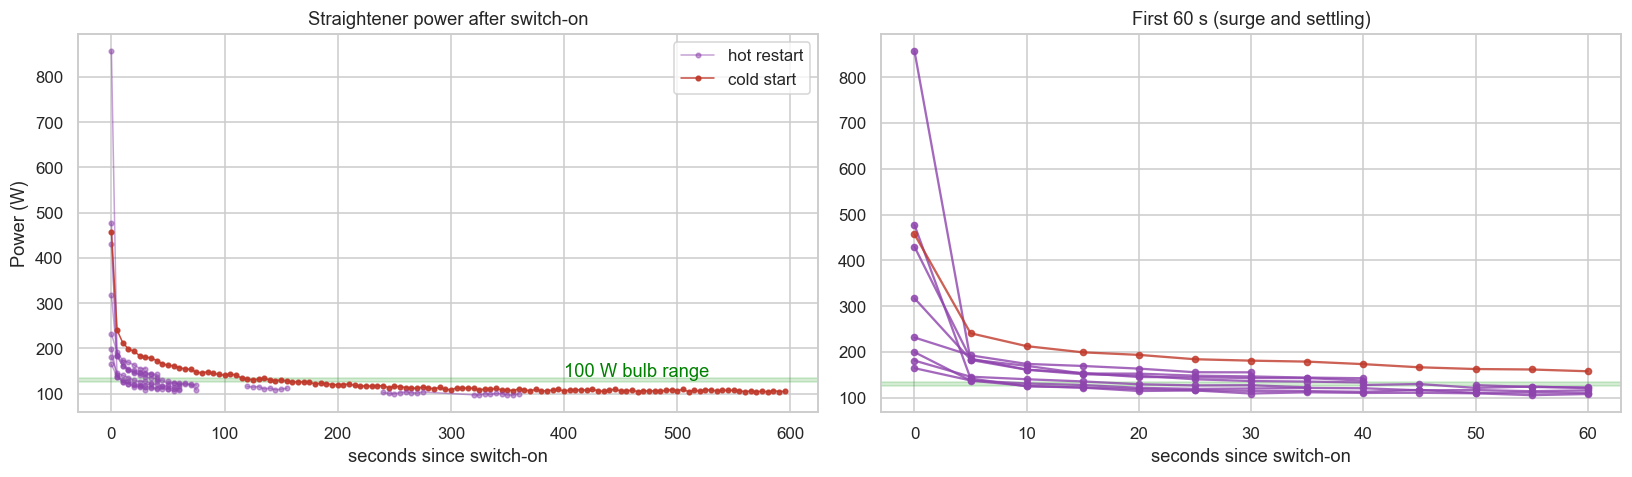

In [9]:
# Power vs time since switch-on for every straightener ON event where it is the only appliance
ons = events[(events.appliance == "Hair straightener") & (events.action == "ON")]
curves = []
for _, e in ons.iterrows():
    nxt = events[(events.run == e.run) & (events.counter > e.counter) & (events.appliance == "Hair straightener")]
    end = nxt["counter"].min() if len(nxt) else e.counter + 600
    seg = df[(df.run == e.run) & (df.counter >= e.counter) & (df.counter < end)].copy()
    # keep only the part where the straightener is the only appliance
    seg = seg[seg["combo"] == "0100"]
    if len(seg) < 3:
        continue
    seg["t_since_on"] = seg["counter"] - e.counter
    seg["kind"] = "cold start" if "cold" in str(e.note) else "hot restart"
    seg["event"] = f"run{e.run}@{e.counter}"
    curves.append(seg)
curves = pd.concat(curves)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for (ev, g) in curves.groupby("event"):
    kind = g["kind"].iloc[0]
    axes[0].plot(g["t_since_on"], g["power_W"], marker="o", ms=3, lw=1,
                 color="#c0392b" if kind == "cold start" else "#8e44ad", alpha=0.9 if kind == "cold start" else 0.5,
                 label=kind)
h, l = axes[0].get_legend_handles_labels(); u = dict(zip(l, h))
axes[0].legend(u.values(), u.keys())
axes[0].axhspan(125, 135, color=COLORS["bulb_100W"], alpha=0.2)
axes[0].text(400, 137, "100 W bulb range", color="green")
axes[0].set_xlabel("seconds since switch-on"); axes[0].set_ylabel("Power (W)")
axes[0].set_title("Straightener power after switch-on")

zoom = curves[curves.t_since_on <= 60]
for (ev, g) in zoom.groupby("event"):
    kind = g["kind"].iloc[0]
    axes[1].plot(g["t_since_on"], g["power_W"], marker="o", ms=4,
                 color="#c0392b" if kind == "cold start" else "#8e44ad", alpha=0.8)
axes[1].axhspan(125, 135, color=COLORS["bulb_100W"], alpha=0.2)
axes[1].set_xlabel("seconds since switch-on"); axes[1].set_title("First 60 s (surge and settling)")
fig.tight_layout(); save(fig, "06_straightener_heatup"); plt.show()

- **Cold start:** a surge (≈ 457 W) in the first sample, then power falls steadily (≈ 213 W after 10 s, ≈ 154 W after
  1 min, ≈ 105 W after 10 min).
- **Hot restarts:** a short surge in the first sample, then it settles at ≈ 110 – 130 W within 5 – 10 s, which is
  **inside the 100 W bulb's range**.
- So the straightener is easy to recognise **at the moment it switches on**, but hard to recognise later from a
  single reading. This motivates an **event-based** model.

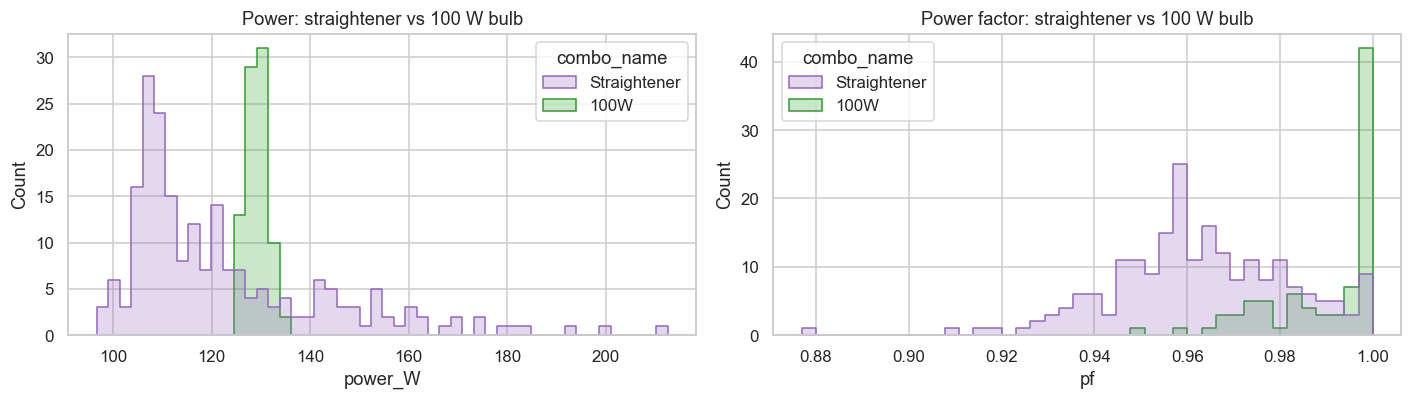

combo_name        100W  Straightener
power_W count   85.000       212.000
        mean   129.229       122.976
        std      2.128        21.025
        min    124.600        96.700
        25%    127.500       108.075
        50%    129.200       115.950
        75%    130.600       131.275
        max    134.600       212.600
pf      count   85.000       212.000
        mean     0.990         0.963
        std      0.012         0.019
        min      0.949         0.877
        25%      0.982         0.952
        50%      0.995         0.962
        75%      1.000         0.976
        max      1.000         1.000

In [10]:
pair = steady[steady.combo.isin(["0100", "0001"])]
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
pal = {"Straightener": COLORS["hair_straightener"], "100W": COLORS["bulb_100W"]}
sns.histplot(pair, x="power_W", hue="combo_name", bins=50, ax=axes[0], palette=pal, element="step")
axes[0].set_title("Power: straightener vs 100 W bulb")
sns.histplot(pair, x="pf", hue="combo_name", bins=40, ax=axes[1], palette=pal, element="step")
axes[1].set_title("Power factor: straightener vs 100 W bulb")
fig.tight_layout(); save(fig, "07_straightener_vs_100W"); plt.show()

pair.groupby("combo_name")[["power_W", "pf"]].describe().T.round(3)

## 6. Switching moments (transition samples)

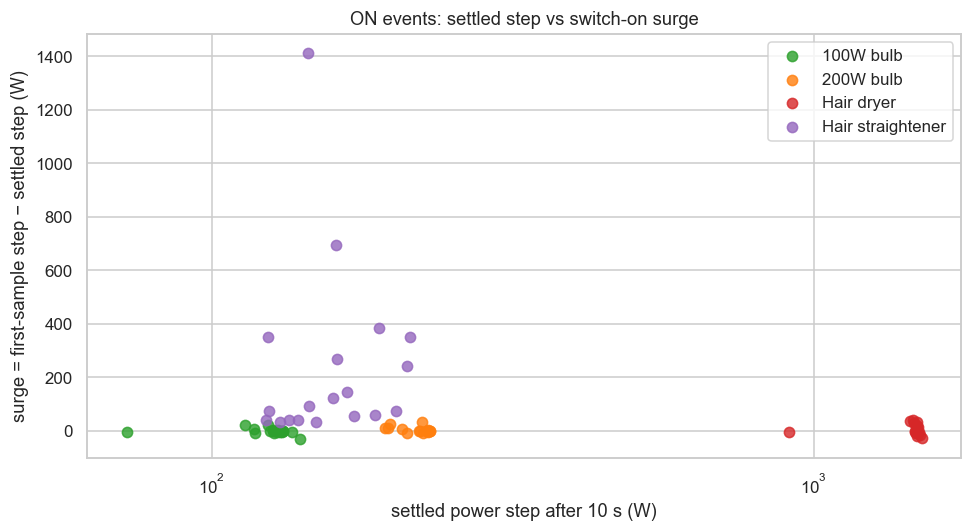

,step_W,settled_step_W,surge_W
appliance,,,
100W bulb,127.8,128.2,-0.6
200W bulb,223.9,223.6,0.9
Hair dryer,1485.0,1480.4,-1.7
Hair straightener,276.1,158.8,91.9


In [11]:
ev = events.merge(df[["run", "counter", "power_W"]], on=["run", "counter"], how="left")
prev = df[["run", "counter", "power_W"]].copy(); prev["counter"] += 5
ev = ev.merge(prev.rename(columns={"power_W": "power_before"}), on=["run", "counter"], how="left")
nxt = df[["run", "counter", "power_W"]].copy(); nxt["counter"] -= 10
ev = ev.merge(nxt.rename(columns={"power_W": "power_after_10s"}), on=["run", "counter"], how="left")
ev["step_W"] = ev["power_W"] - ev["power_before"]
ev["settled_step_W"] = ev["power_after_10s"] - ev["power_before"]
ev["surge_W"] = ev["step_W"] - ev["settled_step_W"]
ev_on = ev[ev.action == "ON"].dropna(subset=["step_W", "settled_step_W"])

fig, ax = plt.subplots(figsize=(9, 5))
for app, g in ev_on.groupby("appliance"):
    key = {"Hair dryer": "hair_dryer", "Hair straightener": "hair_straightener",
           "200W bulb": "bulb_200W", "100W bulb": "bulb_100W"}[app]
    ax.scatter(g["settled_step_W"], g["surge_W"], label=app, color=COLORS[key], s=45, alpha=0.8)
ax.set_xscale("symlog", linthresh=100)
ax.set_xlabel("settled power step after 10 s (W)")
ax.set_ylabel("surge = first-sample step − settled step (W)")
ax.set_title("ON events: settled step vs switch-on surge")
ax.legend()
fig.tight_layout(); save(fig, "08_on_event_signatures"); plt.show()

ev_on.groupby("appliance")[["step_W", "settled_step_W", "surge_W"]].median().round(1)

At the moment of switching ON, the appliances are much easier to tell apart:

- the **bulbs** give a clean step (no surge) of ≈ +129 W or ≈ +227 W;
- the **straightener** usually gives a **surge** in the first sample that disappears over the next samples (median
  ≈ +92 W, up to +1,400 W). Some restarts show only a small surge because the 5-second logging can miss the peak, so
  the decaying power after the step is a second, more reliable clue;
- the **dryer** gives a huge ≈ +1,490 W step.

This is the information an event-based model (Model B) will use.

## 7. Voltage and frequency: supply, not appliances

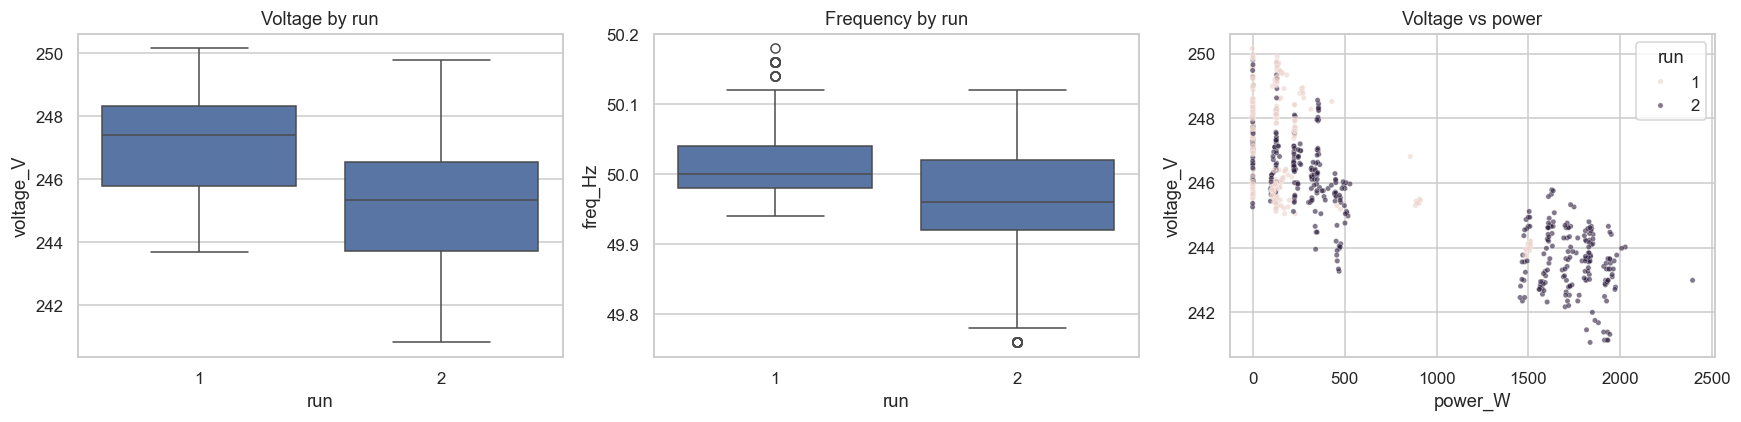

voltage_V        freq_Hz       
         mean    std    mean    std
run                                
1     247.120  1.505  50.016  0.045
2     245.195  1.794  49.959  0.079

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.boxplot(df, x="run", y="voltage_V", ax=axes[0]); axes[0].set_title("Voltage by run")
sns.boxplot(df, x="run", y="freq_Hz", ax=axes[1]); axes[1].set_title("Frequency by run")
sns.scatterplot(df.sample(800, random_state=0), x="power_W", y="voltage_V", hue="run", ax=axes[2], s=12, alpha=0.6)
axes[2].set_title("Voltage vs power")
fig.tight_layout(); save(fig, "09_voltage_frequency"); plt.show()

df.groupby("run")[["voltage_V", "freq_Hz"]].agg(["mean", "std"]).round(3)

Voltage differs between the morning and evening runs (time-of-day grid conditions), and dips a little when the dryer
is on. Frequency only reflects the grid. Using them as inputs would let a model learn **"which session"** instead of
**"which appliance"**, and would not generalise to another day. They are excluded from the model inputs (current
already captures the load).

## 8. Correlation between measurements and targets

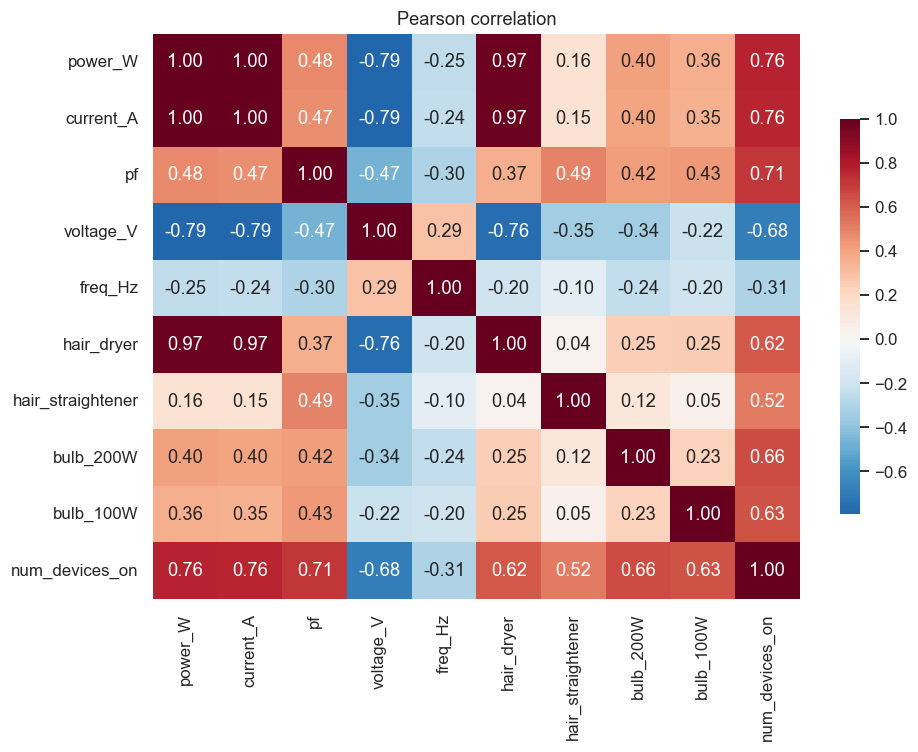

In [13]:
cols = ["power_W", "current_A", "pf", "voltage_V", "freq_Hz"] + APPLIANCES + ["num_devices_on"]
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(df[cols].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax, cbar_kws={"shrink": 0.7})
ax.set_title("Pearson correlation")
fig.tight_layout(); save(fig, "10_correlation"); plt.show()

- `power_W` and `current_A` are almost perfectly correlated (≈ 1.00): current is ≈ power / voltage. Keeping both is
  harmless for tree models but adds little.
- The dryer dominates the correlation with power. The small appliances have weak *linear* correlation with power,
  so non-linear models and better features are needed.

## 9. Are the appliance powers additive?

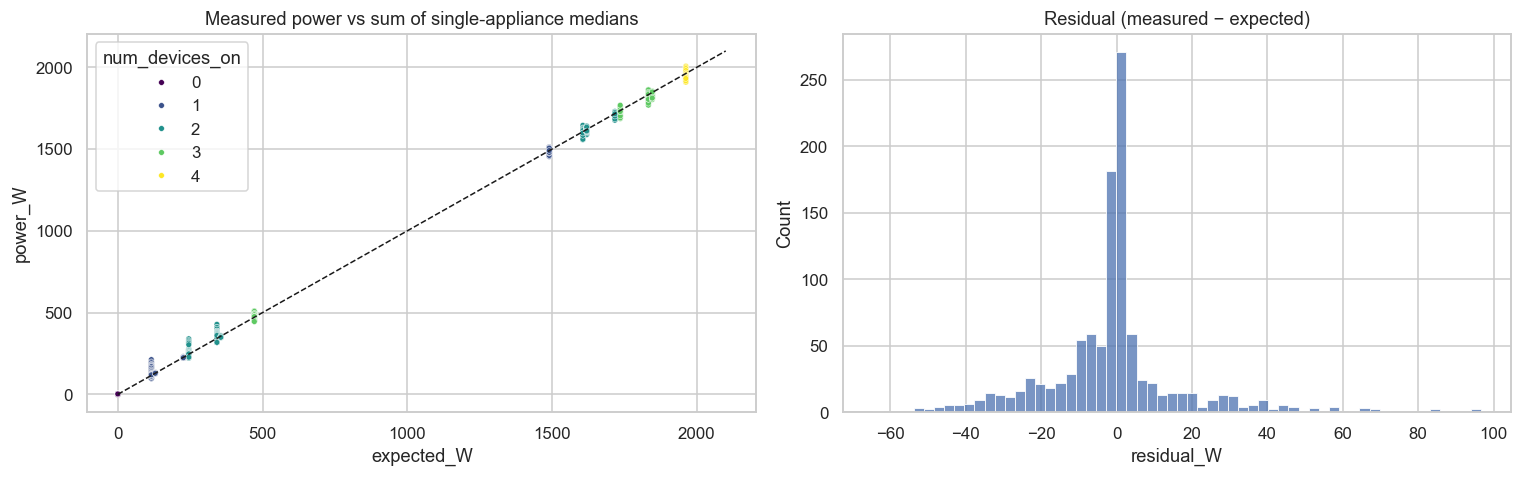

Typical single-appliance power (W): {'Dryer': 1490.5, 'Straightener': 115.9, '200W': 226.5, '100W': 129.2}
{'count': 1069.0, 'mean': -0.9, 'std': 18.4, 'min': -64.5, '25%': -7.8, '50%': -0.2, '75%': 2.4, 'max': 96.6}


In [14]:
alone = steady[steady.num_devices_on == 1]
typ = {a: alone[alone[a] == 1]["power_W"].median() for a in APPLIANCES}
steady_e = steady.copy()
steady_e["expected_W"] = sum(steady_e[a] * typ[a] for a in APPLIANCES)
steady_e["residual_W"] = steady_e["power_W"] - steady_e["expected_W"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.scatterplot(steady_e, x="expected_W", y="power_W", hue="num_devices_on", palette="viridis", s=14, ax=axes[0])
axes[0].plot([0, 2100], [0, 2100], "k--", lw=1)
axes[0].set_title("Measured power vs sum of single-appliance medians")
sns.histplot(steady_e, x="residual_W", bins=60, ax=axes[1])
axes[1].set_title("Residual (measured − expected)")
fig.tight_layout(); save(fig, "11_additivity"); plt.show()

print("Typical single-appliance power (W):", {SHORT[k]: round(v, 1) for k, v in typ.items()})
print(steady_e["residual_W"].describe().round(1).to_dict())

Powers add up closely: the residual has a spread of only ≈ ±18 W (all residuals within −65 … +97 W, the tails come
from the straightener's warm-up drift). This means:

- the problem is a classic **NILM** (non-intrusive load monitoring) problem: total power = sum of appliance powers;
- a **power-sum consistency check** can be used to correct an event-based model when it misses a switch.

## 10. Why a random train/test split would be misleading

Correlation of power with the previous sample: 0.940
Share of samples with the same combination as the previous sample: 88.9%


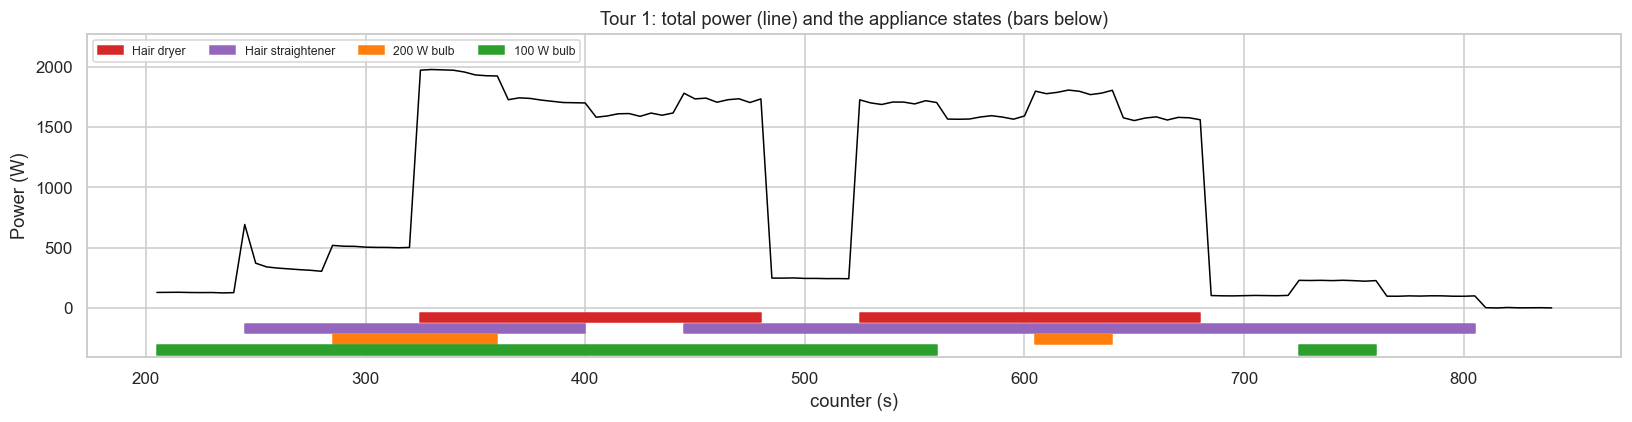

In [15]:
lag = df.groupby("source_file", observed=True)["power_W"].shift(1)
same_label = (df["combo"] == df.groupby("source_file", observed=True)["combo"].shift(1))
print(f"Correlation of power with the previous sample: {df['power_W'].corr(lag):.3f}")
print(f"Share of samples with the same combination as the previous sample: {same_label.mean():.1%}")

fig, ax = plt.subplots(figsize=(15, 4))
blk = df[df.block == "E_tour1"]
ax.plot(blk["counter"], blk["power_W"], color="black", lw=1)
ymax = blk["power_W"].max()
for i, a in enumerate(APPLIANCES):
    on = blk[a].values == 1
    ax.fill_between(blk["counter"], -120 - i * 90, -40 - i * 90, where=on, color=COLORS[a], step="mid")
ax.legend(handles=[mpatches.Patch(color=COLORS[a], label=APPLIANCE_NAMES[a]) for a in APPLIANCES],
          loc="upper left", ncol=4, fontsize=8)
ax.set_ylim(-120 - 3 * 90 - 20, ymax * 1.15)
ax.set_xlabel("counter (s)"); ax.set_ylabel("Power (W)")
ax.set_title("Tour 1: total power (line) and the appliance states (bars below)")
fig.tight_layout(); save(fig, "12_timeline_tour1"); plt.show()

About 89 % of samples have the same label as the sample before, and neighbouring samples are near-copies. A random row
split would put almost identical rows in train and test and **overstate accuracy**. Therefore:

- **model selection / hyper-parameter tuning:** grouped cross-validation, one protocol block per fold
  (*leave-one-block-out*);
- **final score:** only on the untouched `F_test` block.

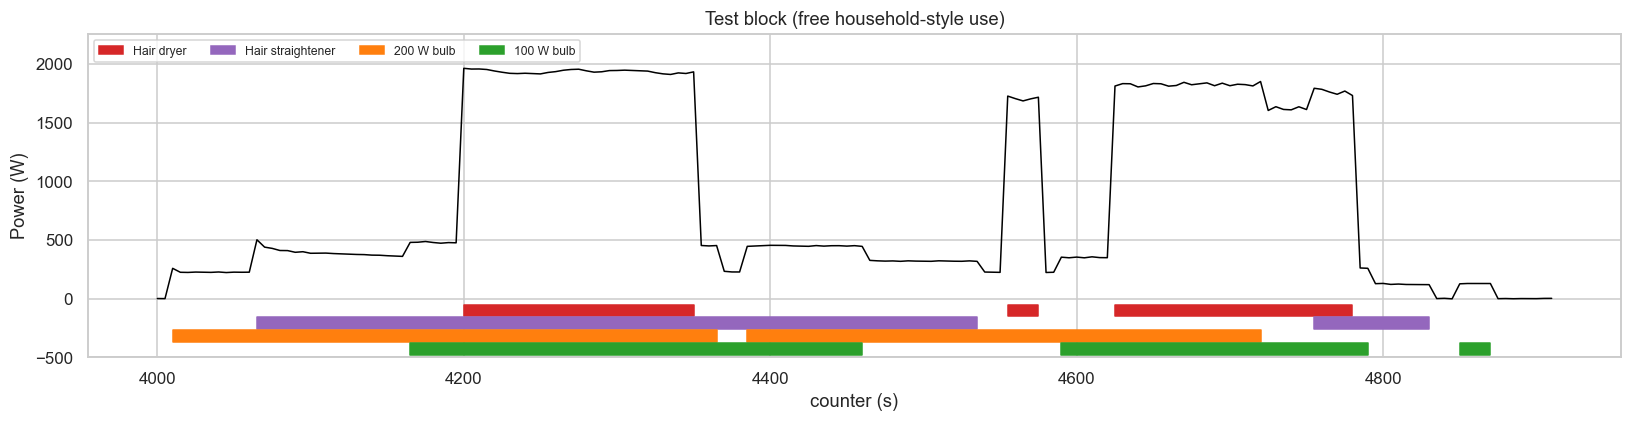

In [16]:
fig, ax = plt.subplots(figsize=(15, 4))
blk = test
ax.plot(blk["counter"], blk["power_W"], color="black", lw=1)
for i, a in enumerate(APPLIANCES):
    on = blk[a].values == 1
    ax.fill_between(blk["counter"], -150 - i * 110, -50 - i * 110, where=on, color=COLORS[a], step="mid")
ax.legend(handles=[mpatches.Patch(color=COLORS[a], label=APPLIANCE_NAMES[a]) for a in APPLIANCES],
          loc="upper left", ncol=4, fontsize=8)
ax.set_ylim(-150 - 3 * 110 - 20, blk["power_W"].max() * 1.15)
ax.set_xlabel("counter (s)"); ax.set_ylabel("Power (W)")
ax.set_title("Test block (free household-style use)")
fig.tight_layout(); save(fig, "13_timeline_test"); plt.show()

## 11. Switch events

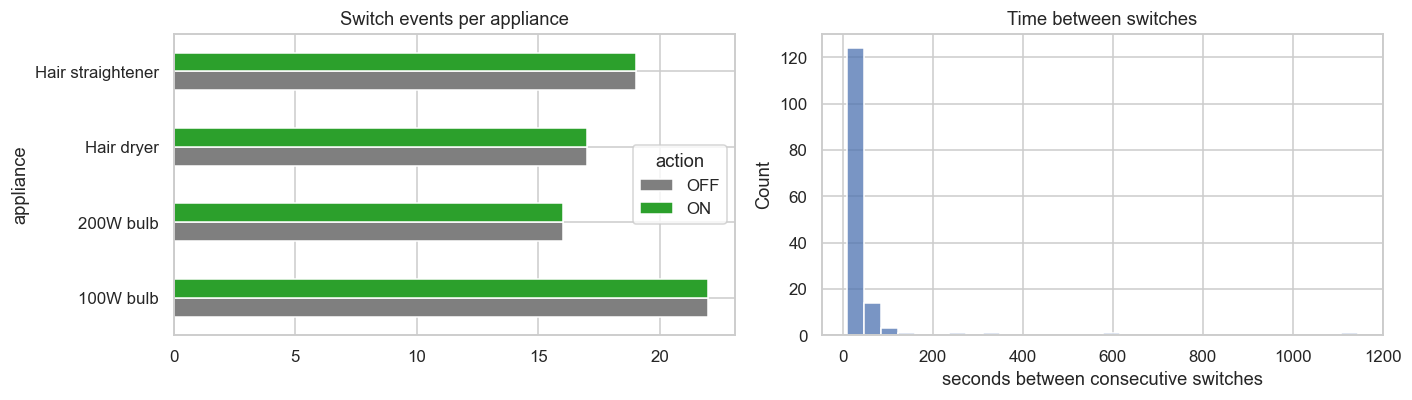

Median gap between switches: 40 s, min: 10 s


In [17]:
ev_gap = events.groupby("run")["counter"].diff().dropna()
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
pd.crosstab(events["appliance"], events["action"]).plot.barh(ax=axes[0], color=["#7f7f7f", "#2ca02c"])
axes[0].set_title("Switch events per appliance")
sns.histplot(ev_gap, bins=30, ax=axes[1])
axes[1].set_xlabel("seconds between consecutive switches"); axes[1].set_title("Time between switches")
fig.tight_layout(); save(fig, "14_switch_events"); plt.show()
print(f"Median gap between switches: {ev_gap.median():.0f} s, min: {ev_gap.min():.0f} s")

## Key findings

1. **Clean, complete dataset:** all 16 combinations, consistent labels, no missing samples.
2. **Easy appliances:** the hair dryer (≈ 1,490 W) and the 200 W bulb (≈ 227 W, PF 1.00) have distinct signatures.
3. **The hard pair:** a hot straightener (≈ 105 – 130 W) overlaps the 100 W bulb (≈ 129 W). Power factor helps
   (≈ 0.96 vs ≈ 1.00) but not completely, and combinations containing one or the other overlap in total power.
4. **Time matters:** the straightener is clearly recognisable at switch-on (surge, then decaying power), so features
   from recent history and an **event-based model** should outperform a single-reading model.
5. **Inputs:** use power, current and power factor (+ features derived from their history). Exclude voltage,
   frequency, energy and counter.
6. **Evaluation:** leave-one-block-out CV for tuning, `F_test` for the final score. Never a random split.
7. **Additive loads:** total power ≈ sum of appliance powers, which enables a power-sum consistency check.

Next: **03 · Feature Engineering**.